<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Procesamiento de Lenguaje Natural**

## **Desafio, Traductor**


**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**


Nombre(s):

- Alejandro Valle


### **Consigna**

- Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
- Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
- Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
- Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
- Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales**

- Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
- Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
- Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.


## Resolución

Partí del traductor seq2seq que vimos en la clase 6 (inglés → español, encoder y decoder con LSTM y GloVe en el encoder) y lo fui extendiendo:

1. Mas datos y oraciones mas largas: 50.000 pares en vez de 10.000, y en lugar de cortar las oraciones en 20/22 palabras dejo que el largo maximo sea el de la oración mas larga.
2. Probe cuatro tamaños de LSTM (64, 128, 256 y 512 neuronas) dejando todo lo demás igual, para ver que tanto cambia.
3. Para evaluar uso la pérdida y la accuracy sin contar el padding, y BLEU sobre un conjunto de test. Tambien veo como cambia el BLEU segun el largo de la oración y saco varios ejemplos para ver que tal traduce de verdad.
4. De lo opcional, compare greedy contra beam search y contra muestreo con temperatura.

La arquitectura, el dropout, el optimizador (Adam) y los callbacks son los de clase. Lo corri en Colab con una T4, y los pesos de cada modelo se guardan en Drive para no tener que reentrenar todo si se corta la sesión (que en Colab pasa seguido).


In [1]:
import json
import os
import pickle
import re
import sys
import time
import urllib.request
import warnings
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from nltk.translate.bleu_score import corpus_bleu
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import LSTM, Dense, Dropout, Embedding, Input
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer, text_to_word_sequence

# el dataset ya se mezcla en tf.data: este aviso de Keras no aplica
warnings.filterwarnings("ignore", message=".*`shuffle=True` was passed.*")
# nltk avisa cuando un grupo de oraciones no tiene ningún 4-grama en común (BLEU = 0)
warnings.filterwarnings("ignore", module="nltk")
# al recargar pesos guardados el optimizador no se usa: este aviso no aplica
warnings.filterwarnings("ignore", message="Skipping variable loading for optimizer")
pd.set_option("display.max_colwidth", None)

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")

TensorFlow 2.21.0 | Keras 3.13.2


### GPU

Entrenar los cuatro modelos en CPU tarda horas, asi que si Colab no me da GPU prefiero que el notebook se detenga aqui y me avise, en vez de quedarse entrenando toda la tarde.


In [2]:
# para correrlo igual en CPU (horas), poner REQUIRE_GPU = False
REQUIRE_GPU = True

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    details = tf.config.experimental.get_device_details(gpus[0])
    print(f"GPU: {details.get('device_name', gpus[0].name)}")
elif REQUIRE_GPU:
    raise RuntimeError(
        "No hay GPU. En Colab: Entorno de ejecución > Cambiar tipo de entorno de ejecución > "
        "GPU T4, y volver a ejecutar todo. Para entrenar igual en CPU, poner REQUIRE_GPU = False."
    )
else:
    print("No hay GPU: se entrena en CPU (REQUIRE_GPU = False)")

GPU: Tesla T4


### Configuración

Aqui estan todos los hiperparámetros juntos. Para comparar tamaños solo cambio `n_units`; los datos, el vocabulario, el batch y el learning rate son los mismos para todos, asi las diferencias vienen solo del tamaño de las LSTM.


In [3]:
SEED = 40  # misma semilla que en clase para mezclar el corpus

NUM_SENTENCES = 50_000  # clase: 10.000 pares
MAX_VOCAB_SIZE = 10_000  # clase: 8.000 (ver la cobertura del vocabulario más abajo)
EMBED_DIM = 50  # GloVe de 50 dimensiones, como en clase
DROPOUT = 0.3  # como en clase

UNITS_LIST = [64, 128, 256, 512]  # neuronas de las LSTM a comparar (clase: 256)
BATCH_SIZE = 128  # clase: 64
LEARNING_RATE = 1e-3  # clase: 5e-4
EPOCHS = 30  # tope, como en clase: EarlyStopping corta antes

VAL_FRACTION = 0.10  # fracción de las oraciones en inglés distintas
TEST_FRACTION = 0.05
N_STRATEGY_EVAL = 500  # oraciones de test para comparar estrategias de decodificación

CLASS_MAX_INPUT_LEN, CLASS_MAX_OUT_LEN = 20, 22  # longitudes fijas del notebook de clase

Los pesos y el historial de cada modelo se guardan en `MODELS_DIR`. En Colab es una carpeta de Drive para no perderlos si se desconecta la sesión (al principio pide autorización).


In [4]:
# En Google Colab los archivos de la sesión se pierden al desconectarse: se guardan en Drive
if "google.colab" in sys.modules:
    from google.colab import drive

    drive.mount("/content/drive")
    MODELS_DIR = Path("/content/drive/MyDrive/nlp1_models/desafio4")
else:
    MODELS_DIR = Path("models_desafio4")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Los pesos y las curvas se guardan en: {MODELS_DIR.resolve()}")

Mounted at /content/drive
Los pesos y las curvas se guardan en: /content/drive/MyDrive/nlp1_models/desafio4


### Datos

Uso el mismo corpus de clase: los pares inglés-español de [Tatoeba](https://tatoeba.org) que publica TensorFlow (`spa-eng`, como 119.000 pares). Son oraciones cortitas y bastante coloquiales. En el archivo vienen ordenadas de la mas corta a la mas larga, por eso primero las mezclo y despues tomo el subconjunto.


In [5]:
DATA_URL = "http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
DATA_PATH = Path("spa-eng/spa.txt")

if not DATA_PATH.exists():
    urllib.request.urlretrieve(DATA_URL, "spa-eng.zip")
    with zipfile.ZipFile("spa-eng.zip") as zf:
        zf.extractall(".")

with open(DATA_PATH, encoding="utf-8") as f:
    lines = f.read().split("\n")[:-1]

# mismo mezclado que en clase
np.random.seed(SEED)
np.random.shuffle(lines)

all_pairs = [line.rstrip().split("\t")[:2] for line in lines if "\t" in line]
print(f"Pares en el corpus completo: {len(all_pairs):,}")

Pares en el corpus completo: 118,964


In [6]:
# Tatoeba repite oraciones en inglés con varias traducciones válidas ("Go." -> "Ve.", "Vete.",
# "Vaya."). Guardamos todas las traducciones de cada oración: son las referencias del BLEU
all_translations = defaultdict(list)
for en, es in all_pairs:
    all_translations[en].append(es)

pairs = all_pairs[:NUM_SENTENCES]
input_sentences = [en for en, _ in pairs]
target_sentences = [es for _, es in pairs]
output_sentences = [es + " <eos>" for es in target_sentences]
output_sentences_inputs = ["<sos> " + es for es in target_sentences]

unique_inputs = set(input_sentences)
n_multi = sum(len(all_translations[en]) > 1 for en in unique_inputs)
print(f"Pares usados: {len(pairs):,} (clase: 10.000)")
print(f"Oraciones en inglés distintas: {len(unique_inputs):,}")
print(f"... con más de una traducción en el corpus: {n_multi:,}\n")

print(input_sentences[0])
print(output_sentences[0])
print(output_sentences_inputs[0])

Pares usados: 50,000 (clase: 10.000)
Oraciones en inglés distintas: 46,724
... con más de una traducción en el corpus: 8,682

Somebody stole my car.
Alguien robó mi auto. <eos>
<sos> Alguien robó mi auto.


### Tokenización

Cada idioma tiene su `Tokenizer` de Keras (pasa todo a minúsculas, quita la puntuación y se queda con las `MAX_VOCAB_SIZE` palabras mas frecuentes). Algunos detalles:

- Contracciones: GloVe tiene las contracciones separadas (`do n't`, `i 'm`, `tom 's`), pero el tokenizer de Keras deja `don't` o `i'm` como una sola palabra, y esa palabra no existe en GloVe. Entonces antes de tokenizar el inglés separo las contracciones igual que GloVe, y asi cada pedazo tiene su vector.
- El tokenizer del español lo ajusto con las entradas y las salidas del decoder, asi `<sos>` y `<eos>` aparecen una vez por oración y quedan entre las palabras mas frecuentes.
- Los índices del tokenizer empiezan en 1 (el 0 es el padding), por eso el `Embedding` tiene `len(word_index) + 1` filas.


In [7]:
def split_clitics(text):
    """Separa las contracciones del inglés como el vocabulario de GloVe:
    "don't" -> "do n't", "can't" -> "ca n't", "I'm" -> "I 'm", "Tom's" -> "Tom 's"."""
    text = text.replace("’", "'")
    text = re.sub(r"n't\b", " n't", text, flags=re.IGNORECASE)
    return re.sub(r"'(s|m|re|ve|ll|d)\b", r" '\1", text, flags=re.IGNORECASE)


print(split_clitics("I'm sure Tom's dog can't swim, but I don't know why."))

input_texts = [split_clitics(s) for s in input_sentences]
input_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)
input_tokenizer.fit_on_texts(input_texts)
input_integer_seq = input_tokenizer.texts_to_sequences(input_texts)
word2idx_inputs = input_tokenizer.word_index

# como en clase se eliminan los signos de puntuación sin tocar < y > (de <sos> y <eos>);
# se agrega ¡ para que "¡hola" y "hola" sean la misma palabra
OUTPUT_FILTERS = '!"#$%&()*+,-./:;=¿?¡@[\\]^_`{|}~\t\n'
output_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, filters=OUTPUT_FILTERS)
output_tokenizer.fit_on_texts(output_sentences_inputs + output_sentences)
output_integer_seq = output_tokenizer.texts_to_sequences(output_sentences)
output_input_integer_seq = output_tokenizer.texts_to_sequences(output_sentences_inputs)
word2idx_outputs = output_tokenizer.word_index

# índices válidos: de 0 (padding) a num_words - 1
nb_words = min(MAX_VOCAB_SIZE, len(word2idx_inputs) + 1)
num_words_output = min(MAX_VOCAB_SIZE, len(word2idx_outputs) + 1)
sos_idx, eos_idx = word2idx_outputs["<sos>"], word2idx_outputs["<eos>"]
assert max(sos_idx, eos_idx) < num_words_output

# así quedaba <sos> con el ajuste de clase
class_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, filters=OUTPUT_FILTERS)
class_tokenizer.fit_on_texts(["<sos>", "<eos>"] + output_sentences)
print(
    f"\nCon el ajuste de clase, <sos> tendría el índice {class_tokenizer.word_index['<sos>']:,} "
    f"(vocabulario máximo: {MAX_VOCAB_SIZE:,})"
)
print(f"Ahora: <sos> = {sos_idx}, <eos> = {eos_idx}\n")


def token_coverage(tokenizer, num_words, skip=("<sos>", "<eos>")):
    """Fracción de las apariciones de palabras que quedan dentro del vocabulario."""
    counts = {w: c for w, c in tokenizer.word_counts.items() if w not in skip}
    kept = sum(c for w, c in counts.items() if tokenizer.word_index[w] < num_words)
    return kept / sum(counts.values())


pd.DataFrame(
    {
        "palabras distintas": [len(word2idx_inputs), len(word2idx_outputs) - 2],
        "tamaño del vocabulario (con el 0)": [nb_words, num_words_output],
        "% de apariciones dentro del vocabulario": [
            round(100 * token_coverage(input_tokenizer, nb_words), 2),
            round(100 * token_coverage(output_tokenizer, num_words_output), 2),
        ],
    },
    index=["inglés (encoder)", "español (decoder)"],
)

I 'm sure Tom 's dog ca n't swim, but I do n't know why.

Con el ajuste de clase, <sos> tendría el índice 9,472 (vocabulario máximo: 10,000)
Ahora: <sos> = 1, <eos> = 2



,palabras distintas,tamaño del vocabulario (con el 0),% de apariciones dentro del vocabulario
inglés (encoder),9706,9707,100.00
español (decoder),17799,10000,97.44


Nota: las palabras que quedan fuera del vocabulario no se cambian por un token especial, `texts_to_sequences` simplemente las borra. En español esto pega sobre todo en nombres propios y conjugaciones raras, que el modelo nunca va a poder generar.

### Largo de las secuencias


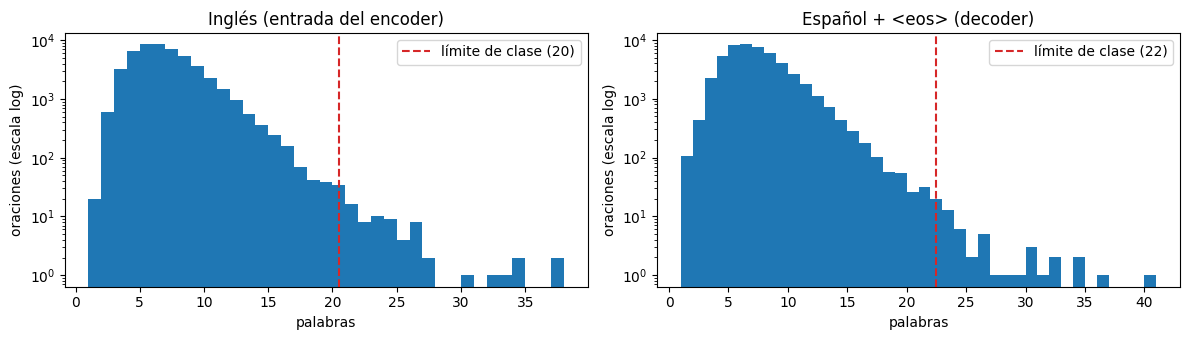

,media,mediana,p90,p99,p99.9,máx
inglés (encoder),6.6,6.0,10.0,15.0,21.0,37.0
español + <eos> (decoder),6.9,7.0,10.0,16.0,22.0,40.0


In [8]:
input_lens = np.array([len(s) for s in input_integer_seq])
output_lens = np.array([len(s) for s in output_integer_seq])  # palabras + <eos>
assert (output_lens == np.array([len(s) for s in output_input_integer_seq])).all()

length_stats = (
    pd.DataFrame(
        {
            "inglés (encoder)": pd.Series(input_lens).describe(percentiles=[0.5, 0.9, 0.99, 0.999]),
            "español + <eos> (decoder)": pd.Series(output_lens).describe(
                percentiles=[0.5, 0.9, 0.99, 0.999]
            ),
        }
    )
    .T[["mean", "50%", "90%", "99%", "99.9%", "max"]]
    .round(1)
)
length_stats.columns = ["media", "mediana", "p90", "p99", "p99.9", "máx"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, lens, limit, title in [
    (axes[0], input_lens, CLASS_MAX_INPUT_LEN, "Inglés (entrada del encoder)"),
    (axes[1], output_lens, CLASS_MAX_OUT_LEN, "Español + <eos> (decoder)"),
]:
    ax.hist(lens, bins=range(1, lens.max() + 2), color="tab:blue")
    ax.axvline(limit + 0.5, color="tab:red", linestyle="--", label=f"límite de clase ({limit})")
    ax.set_yscale("log")
    ax.set_xlabel("palabras")
    ax.set_ylabel("oraciones (escala log)")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

length_stats

Casi todas las oraciones son cortas, pero hay una cola bastante mas larga que las 20/22 palabras que se usaban en clase. Para no cortar ninguna, uso como largo maximo el de la oración mas larga del conjunto. Eso mete un montón de padding, pero no pasa nada porque la pérdida lo ignora (lo explico mas abajo).


In [9]:
max_input_len = int(input_lens.max())
max_out_len = int(output_lens.max())

# como en clase: padding al inicio en el encoder (así el último estado de la LSTM corresponde
# a la última palabra) y al final en el decoder
encoder_input_sequences = pad_sequences(input_integer_seq, maxlen=max_input_len)
decoder_input_sequences = pad_sequences(
    output_input_integer_seq, maxlen=max_out_len, padding="post"
)
decoder_output_sequences = pad_sequences(output_integer_seq, maxlen=max_out_len, padding="post")

assert (decoder_input_sequences[:, 0] == sos_idx).all()
assert encoder_input_sequences.max() < nb_words
assert decoder_output_sequences.max() < num_words_output

# qué hacía el truncado de clase con estos datos
class_dec_in = pad_sequences(output_input_integer_seq, maxlen=CLASS_MAX_OUT_LEN, padding="post")
n_truncated = int(np.sum((input_lens > CLASS_MAX_INPUT_LEN) | (output_lens > CLASS_MAX_OUT_LEN)))
n_lost_sos = int(np.sum(class_dec_in[:, 0] != sos_idx))
print(
    f"max_input_len = {max_input_len} (clase: {CLASS_MAX_INPUT_LEN}) | "
    f"max_out_len = {max_out_len} (clase: {CLASS_MAX_OUT_LEN})"
)
print(f"Pares que la clase hubiera truncado: {n_truncated} ({n_lost_sos} perdían el <sos>)")

pad_share = 1 - (decoder_output_sequences > 0).mean()
print(f"Posiciones de salida del decoder que son padding: {pad_share:.1%}")
print(
    f"Con la accuracy de clase (que cuenta el padding), un modelo que sólo predijera padding "
    f"acertaría el {pad_share:.0%} sin traducir nada"
)

max_input_len = 37 (clase: 20) | max_out_len = 40 (clase: 22)
Pares que la clase hubiera truncado: 76 (39 perdían el <sos>)
Posiciones de salida del decoder que son padding: 82.6%
Con la accuracy de clase (que cuenta el padding), un modelo que sólo predijera padding acertaría el 83% sin traducir nada


### División en train, validación y test

En Tatoeba una misma oración en inglés aparece varias veces con traducciones distintas. Si separaba los pares al azar, la misma oración podia caer en train y en test, y el test iba a medir mas memoria que traducción. Por eso separo las oraciones en inglés distintas (85% / 10% / 5%) y cada par se va al conjunto de su oración.

La validación la uso como en clase, para `EarlyStopping` y `ReduceLROnPlateau`. El test lo dejo para el final: traduzco una vez cada oración y la comparo con todas las traducciones que tiene en el corpus completo.

El dataset de `tf.data` lo armo con los índices enteros (nada de one-hot, que con 10.000 palabras ocupa muchísima memoria) y se mezcla en cada epoch.


In [10]:
unique_en = sorted(unique_inputs)
rng = np.random.default_rng(SEED)
rng.shuffle(unique_en)
n_test = int(len(unique_en) * TEST_FRACTION)
n_val = int(len(unique_en) * VAL_FRACTION)
split_of = {en: "test" for en in unique_en[:n_test]}
split_of.update({en: "val" for en in unique_en[n_test : n_test + n_val]})
split = np.array([split_of.get(en, "train") for en in input_sentences])


def make_dataset(mask, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (
            (encoder_input_sequences[mask], decoder_input_sequences[mask]),
            decoder_output_sequences[mask],
        )
    )
    if shuffle:
        ds = ds.shuffle(int(mask.sum()), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(split == "train", shuffle=True)
val_ds = make_dataset(split == "val")

# test: la primera aparición de cada oración en inglés
first_occurrence = {}
for i, en in enumerate(input_sentences):
    if split[i] == "test":
        first_occurrence.setdefault(en, i)
test_idx = np.array(sorted(first_occurrence.values()))

print(f"Pares de entrenamiento: {np.sum(split == 'train'):,}")
print(f"Pares de validación:    {np.sum(split == 'val'):,}")
print(f"Oraciones de test:      {len(test_idx):,} (inglés distintas)")

Pares de entrenamiento: 42,507
Pares de validación:    5,008
Oraciones de test:      2,336 (inglés distintas)


### Embeddings GloVe para el encoder

Igual que en clase: GloVe de 50 dimensiones para el inglés, congelado (`trainable=False`). El decoder aprende sus propios embeddings para el español.


In [11]:
def _is_valid_pickle(path):
    try:
        with open(path, "rb") as f:
            head = f.read(20)
        return b"<html" not in head.lower() and b"<!doctype" not in head.lower()
    except Exception:
        return False


_PKL_PATH = "gloveembedding.pkl"
_FILE_ID = "1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94"

if not os.path.exists(_PKL_PATH) or not _is_valid_pickle(_PKL_PATH):
    print("Descargando gloveembedding.pkl desde Google Drive...")
    if os.path.exists(_PKL_PATH):
        os.remove(_PKL_PATH)
    try:
        import gdown

        gdown.download(id=_FILE_ID, output=_PKL_PATH, quiet=False)
    except Exception:
        os.system(
            f"curl -L -o {_PKL_PATH} "
            f'"https://drive.google.com/u/0/uc?id={_FILE_ID}&export=download&confirm=t"'
        )
    if not _is_valid_pickle(_PKL_PATH):
        raise ValueError("El archivo descargado no es un pickle válido.")
    print("Descarga completada.")
else:
    print("gloveembedding.pkl ya disponible.")

Descargando gloveembedding.pkl desde Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94
From (redirected): https://drive.google.com/uc?id=1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94&confirm=t&uuid=1eeb23d4-4f4a-4de5-b81a-db6106ce0bd7
To: /content/gloveembedding.pkl
100%|██████████| 525M/525M [00:03<00:00, 137MB/s]

Descarga completada.


In [12]:
def load_glove_embeddings(pkl_path):
    """Carga el pickle de GloVe y devuelve (embeddings, word2idx)."""
    max_bytes = 2**28 - 1
    raw = bytearray()
    sz = os.path.getsize(pkl_path)
    with open(pkl_path, "rb") as f:
        for _ in range(0, sz, max_bytes):
            raw += f.read(max_bytes)
    embeddings = pickle.loads(raw)
    idx_array = np.arange(embeddings.shape[0])
    word2idx = dict(zip(embeddings["word"], idx_array))
    return embeddings, word2idx


def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    return embeddings[i]["embedding"] if i != -1 else np.zeros(n_features)


def build_embedding_matrix(word2idx_inputs, embeddings, word2idx_glove, nb_words, embed_dim=50):
    matrix = np.zeros((nb_words, embed_dim))
    for word, i in word2idx_inputs.items():
        if i < nb_words:
            vec = get_word_embedding(word, embeddings, word2idx_glove, embed_dim)
            if vec is not None and len(vec) > 0:
                matrix[i] = vec
    return matrix


glove_embeddings, glove_word2idx = load_glove_embeddings(_PKL_PATH)
embedding_matrix = build_embedding_matrix(
    word2idx_inputs, glove_embeddings, glove_word2idx, nb_words, EMBED_DIM
)
print(f"Embeddings nulos: {np.sum(np.sum(embedding_matrix**2, axis=1) == 0)} de {nb_words:,} filas")

# ¿cuántas apariciones de palabras quedan sin vector, con y sin separar las contracciones?
tokens_raw = [w for s in input_sentences for w in text_to_word_sequence(s)]
tokens_split = [w for s in input_texts for w in text_to_word_sequence(s)]
missing_raw = Counter(w for w in tokens_raw if w not in glove_word2idx)
missing_split = Counter(w for w in tokens_split if w not in glove_word2idx)
glove_missing_raw = sum(missing_raw.values()) / len(tokens_raw)
glove_missing_split = sum(missing_split.values()) / len(tokens_split)
print(
    f"Apariciones sin vector GloVe: {glove_missing_raw:.1%} sin separar "
    f"las contracciones -> {glove_missing_split:.1%} separándolas"
)
print(f"Más frecuentes sin vector (sin separar): {missing_raw.most_common(8)}")
print(f"Más frecuentes sin vector (separando):   {missing_split.most_common(8)}")

Embeddings nulos: 261 de 9,707 filas
Apariciones sin vector GloVe: 4.8% sin separar las contracciones -> 0.2% separándolas
Más frecuentes sin vector (sin separar): [("don't", 2093), ("i'm", 1581), ("it's", 935), ("didn't", 888), ("can't", 784), ("doesn't", 666), ("i'll", 596), ("you're", 585)]
Más frecuentes sin vector (separando):   [('30', 95), ('2', 75), ('10', 34), ('000', 27), ('5', 24), ('3', 19), ('00', 17), ('20', 15)]


Separar las contracciones si valio la pena: casi todas las palabras sin vector eran justo `don't`, `i'm`, `it's` y compañía, que encima son de las mas frecuentes del corpus. Ya separadas, lo unico que queda sin vector son algunos numeros.


### Modelo seq2seq

La arquitectura es la de clase:

- Encoder: embedding GloVe congelado → dropout → LSTM. De la LSTM solo me quedo con los estados finales `(h, c)`, que son como el resumen de toda la oración en inglés en un vector de `n_units` números (el vector de contexto).
- Decoder: embedding propio del español (de tamaño `n_units`, como en clase) → dropout → LSTM que arranca desde los estados del encoder → `Dense` con softmax sobre el vocabulario en español.
- Se entrena con _teacher forcing_: el decoder recibe la traducción correcta corrida un lugar (`<sos> w1 w2 ...`) y tiene que adivinar la palabra siguiente (`w1 w2 ... <eos>`).

Para traducir armo dos modelos mas que reutilizan las mismas capas (o sea, los mismos pesos ya entrenados): el encoder, que devuelve `(h, c)`, y un decoder que va de a una palabra.

Sobre la pérdida: en clase la pérdida y la accuracy se promediaban sobre todas las posiciones del decoder, incluyendo el relleno. Como casi todo es padding, predecir "0" ahi es facilisimo y la accuracy sale inflada. Aqui las calculo solo sobre las palabras reales (contando `<eos>`). Con esta pérdida el modelo nunca aprende a predecir padding, asi que la accuracy "de clase" ya no tiene sentido y no la registro. De paso, `exp(val_loss)` queda como la perplejidad por palabra.


In [13]:
def masked_loss(y_true, y_pred):
    """Entropía cruzada promedio sobre las posiciones que no son padding."""
    mask = tf.cast(tf.not_equal(y_true, 0), y_pred.dtype)
    loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    return tf.reduce_sum(loss * mask) / tf.reduce_sum(mask)


def masked_accuracy(y_true, y_pred):
    """Fracción de palabras acertadas, sin contar las posiciones de padding."""
    y_true = tf.cast(y_true, tf.int64)
    mask = tf.not_equal(y_true, 0)
    hits = tf.logical_and(tf.equal(tf.argmax(y_pred, axis=-1), y_true), mask)
    return tf.reduce_sum(tf.cast(hits, tf.float32)) / tf.reduce_sum(tf.cast(mask, tf.float32))


def build_seq2seq(n_units):
    """Devuelve (modelo de entrenamiento, encoder de inferencia, decoder de inferencia)."""
    # --- encoder ---
    enc_inputs = Input(shape=(max_input_len,), name="encoder_inputs")
    enc_emb_layer = Embedding(
        input_dim=nb_words,
        output_dim=EMBED_DIM,
        weights=[embedding_matrix],
        trainable=False,
        name="encoder_embedding",
    )
    enc_emb = Dropout(DROPOUT, name="encoder_dropout")(enc_emb_layer(enc_inputs))
    enc_lstm_layer = LSTM(n_units, return_state=True, name="encoder_lstm")
    _, state_h, state_c = enc_lstm_layer(enc_emb)

    # --- decoder ---
    dec_inputs = Input(shape=(max_out_len,), name="decoder_inputs")
    dec_emb_layer = Embedding(
        input_dim=num_words_output, output_dim=n_units, name="decoder_embedding"
    )
    dec_emb = Dropout(DROPOUT, name="decoder_dropout")(dec_emb_layer(dec_inputs))
    dec_lstm_layer = LSTM(n_units, return_sequences=True, return_state=True, name="decoder_lstm")
    dec_out, _, _ = dec_lstm_layer(dec_emb, initial_state=[state_h, state_c])
    dec_dense_layer = Dense(num_words_output, activation="softmax", name="decoder_dense")
    model = Model([enc_inputs, dec_inputs], dec_dense_layer(dec_out), name=f"seq2seq_{n_units}")

    # --- inferencia: mismas capas, sin dropout ---
    _, inf_h, inf_c = enc_lstm_layer(enc_emb_layer(enc_inputs))
    encoder_model = Model(enc_inputs, [inf_h, inf_c], name=f"encoder_{n_units}")

    dec_input_single = Input(shape=(1,), name="dec_input_single")
    dec_state_h_in = Input(shape=(n_units,), name="dec_state_h")
    dec_state_c_in = Input(shape=(n_units,), name="dec_state_c")
    single_out, h_out, c_out = dec_lstm_layer(
        dec_emb_layer(dec_input_single), initial_state=[dec_state_h_in, dec_state_c_in]
    )
    decoder_model = Model(
        [dec_input_single, dec_state_h_in, dec_state_c_in],
        [dec_dense_layer(single_out), h_out, c_out],
        name=f"decoder_{n_units}",
    )
    return model, encoder_model, decoder_model


def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


# la configuración de clase (256 neuronas)
build_seq2seq(256)[0].summary()

Model: "seq2seq_256"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_inputs      │ (None, 37)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_inputs      │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_embedding   │ (None, 37, 50)    │    485,350 │ encoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, 1, 256)    │  2,560,000 │ decoder_inputs[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, 37, 50)    │          0 │ encoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dropout     │ (None, 40, 256)   │          0 │ decoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    314,368 │ encoder_dropout[… │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 1, 256),  │    525,312 │ decoder_dropout[… │
│                     │ (None, 256),      │            │ encoder_lstm[0][… │
│                     │ (None, 256)]      │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dense       │ (None, 1, 10000)  │  2,570,000 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,455,030 (24.62 MB)

 Trainable params: 5,969,680 (22.77 MB)

 Non-trainable params: 485,350 (1.85 MB)

In [14]:
# cómo crece el modelo con el número de neuronas (el embedding GloVe está congelado)
param_rows = []
for n_units in UNITS_LIST:
    m = build_seq2seq(n_units)[0]
    param_rows.append(
        {
            "neuronas LSTM": n_units,
            "parámetros entrenables": count_trainable(m),
            "LSTM (encoder + decoder)": m.get_layer("encoder_lstm").count_params()
            + m.get_layer("decoder_lstm").count_params(),
            "embedding + Dense del decoder": m.get_layer("decoder_embedding").count_params()
            + m.get_layer("decoder_dense").count_params(),
        }
    )
pd.DataFrame(param_rows).set_index("neuronas LSTM")

,parámetros entrenables,LSTM (encoder + decoder),embedding + Dense del decoder
neuronas LSTM,,,
64,1352464,62464,1290000
128,2793232,223232,2570000
256,5969680,839680,5130000
512,13502224,3252224,10250000


### Entrenamiento

Entreno un modelo por cada valor de `UNITS_LIST` con los callbacks de clase: `ReduceLROnPlateau` baja el learning rate a la mitad si la pérdida de validación no mejora en 2 epochs, y `EarlyStopping` corta despues de 4 epochs sin mejorar. Ademas le agregué `ModelCheckpoint` para guardar los pesos de la mejor epoch, y al final me quedo con esos.

Cada modelo guarda en `MODELS_DIR` sus pesos y su historial. Si ya existen, los carga en vez de reentrenar (revisando que sean de los mismos datos y vocabulario). Esto me sirvio un buen porque no entrené los cuatro modelos en la misma sesión de Colab.


In [15]:
# si cambia algo de esto, los pesos guardados no sirven
RUN_CONFIG = {
    "num_sentences": NUM_SENTENCES,
    "seed": SEED,
    "nb_words": int(nb_words),
    "num_words_output": int(num_words_output),
    "max_input_len": max_input_len,
    "max_out_len": max_out_len,
    "embed_dim": EMBED_DIM,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
}


def train_or_load(n_units):
    name = f"lstm_{n_units}"
    weights_path = MODELS_DIR / f"{name}.weights.h5"
    record_path = MODELS_DIR / f"{name}_history.json"

    keras.utils.set_random_seed(SEED)
    model, encoder_model, decoder_model = build_seq2seq(n_units)
    model.compile(
        loss=masked_loss,
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        metrics=[masked_accuracy],
    )

    if weights_path.exists() and record_path.exists():
        record = json.loads(record_path.read_text())
        assert record["config"] == RUN_CONFIG, (
            f"{record_path} se entrenó con otros datos o vocabulario: "
            "borrar sus archivos y reentrenar"
        )
        model.load_weights(weights_path)
        print(
            f"{name}: se cargan los pesos guardados ({record['epochs_run']} epochs, sin reentrenar)"
        )
    else:
        print(f"Entrenando {name}...")
        callbacks = [
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
            EarlyStopping(monitor="val_loss", patience=4, verbose=1),
            ModelCheckpoint(
                str(weights_path), monitor="val_loss", save_best_only=True, save_weights_only=True
            ),
        ]
        start = time.time()
        hist = model.fit(
            train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=2
        )
        seconds = time.time() - start
        model.load_weights(weights_path)  # nos quedamos con la mejor epoch
        record = {
            "n_units": n_units,
            "trainable_params": count_trainable(model),
            "epochs_run": len(hist.history["loss"]),
            "seconds": seconds,
            "history": {k: [float(v) for v in vals] for k, vals in hist.history.items()},
            "config": RUN_CONFIG,
        }
        record_path.write_text(json.dumps(record))
    return {"model": model, "encoder": encoder_model, "decoder": decoder_model, "record": record}

In [16]:
runs = {}
for n_units in UNITS_LIST:
    runs[n_units] = train_or_load(n_units)

lstm_64: se cargan los pesos guardados (30 epochs, sin reentrenar)
lstm_128: se cargan los pesos guardados (30 epochs, sin reentrenar)
Entrenando lstm_256...
Epoch 1/30
333/333 - 37s - 111ms/step - loss: 5.8085 - masked_accuracy: 0.1698 - val_loss: 5.2805 - val_masked_accuracy: 0.2102 - learning_rate: 0.0010
Epoch 2/30
333/333 - 30s - 89ms/step - loss: 4.9262 - masked_accuracy: 0.2342 - val_loss: 4.7714 - val_masked_accuracy: 0.2539 - learning_rate: 0.0010
Epoch 3/30
333/333 - 30s - 90ms/step - loss: 4.4734 - masked_accuracy: 0.2753 - val_loss: 4.4396 - val_masked_accuracy: 0.2884 - learning_rate: 0.0010
Epoch 4/30
333/333 - 30s - 91ms/step - loss: 4.1436 - masked_accuracy: 0.3028 - val_loss: 4.2012 - val_masked_accuracy: 0.3082 - learning_rate: 0.0010
Epoch 5/30
333/333 - 31s - 94ms/step - loss: 3.8749 - masked_accuracy: 0.3266 - val_loss: 4.0035 - val_masked_accuracy: 0.3327 - learning_rate: 0.0010
Epoch 6/30
333/333 - 30s - 91ms/step - loss: 3.6542 - masked_accuracy: 0.3488 - val_lo

### Curvas de entrenamiento


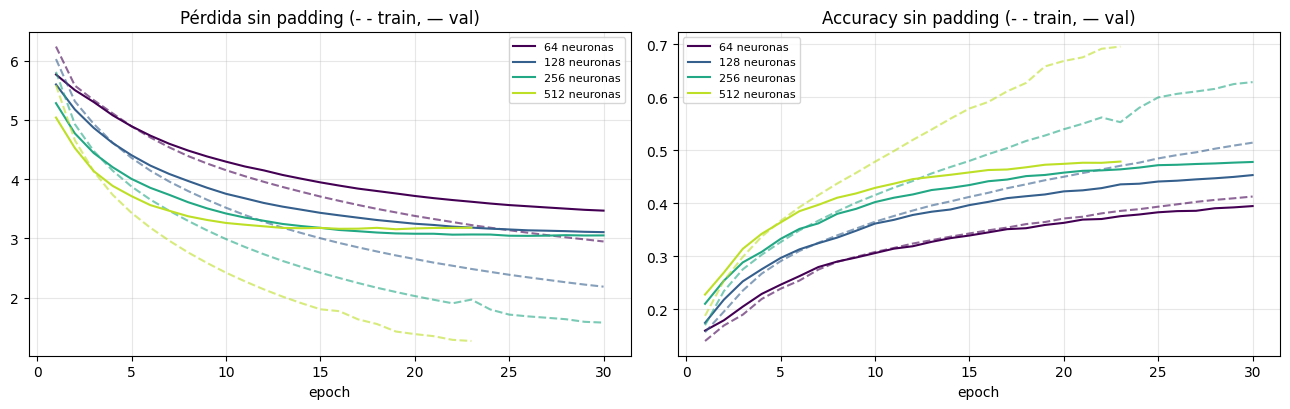

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for (n_units, run), color in zip(runs.items(), plt.cm.viridis(np.linspace(0, 0.9, len(runs)))):
    hist = run["record"]["history"]
    epochs = range(1, len(hist["loss"]) + 1)
    axes[0].plot(epochs, hist["loss"], "--", color=color, alpha=0.6)
    axes[0].plot(epochs, hist["val_loss"], color=color, label=f"{n_units} neuronas")
    axes[1].plot(epochs, hist["masked_accuracy"], "--", color=color, alpha=0.6)
    axes[1].plot(epochs, hist["val_masked_accuracy"], color=color, label=f"{n_units} neuronas")

axes[0].set_title("Pérdida sin padding (- - train, — val)")
axes[1].set_title("Accuracy sin padding (- - train, — val)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Con 64 y 128 neuronas la pérdida de validación seguia bajando cuando llegaron a las 30 epochs, o sea que el early stopping nunca se activó y les faltó entrenar mas. Con 256 la validación ya se aplana hacia el final. Con 512 pasa otra cosa: la pérdida de train baja rapidisimo pero la de validación se estanca bastante antes, y las dos curvas se separan un montón. Eso ya es sobreajuste.

Algo curioso: en 512 la accuracy de validación sigue subiendo un poquito aunque la pérdida ya no mejora. Supongo que el modelo se vuelve mas "seguro" de sus respuestas, tambien de las que tiene mal, y eso castiga la pérdida aunque le atine a alguna palabra mas.


### Inferencia y evaluación con BLEU

Al traducir el decoder ya no tiene la traducción correcta: arranca con `<sos>` y en cada paso recibe la palabra que el mismo generó. En clase se usa greedy (en cada paso, la palabra mas probable). Yo llamo al decoder sobre muchas oraciones a la vez en lugar de hacer un `predict` por palabra y por oración, porque si no traducir todo el test tardaba una eternidad. Las mismas funciones me sirven despues para el muestreo aleatorio.

Para medir la calidad uso BLEU, que basicamente cuenta cuántos n-gramas (de 1 a 4 palabras seguidas) de la traducción aparecen en alguna de las referencias, y castiga las traducciones demasiado cortas. Va de 0 a 100 y lo calculo a nivel corpus. Como referencias uso todas las traducciones que tiene esa oración en el corpus completo, en minúsculas y sin puntuación (igual que lo que sale del modelo).


In [18]:
idx2word_target = {v: k for k, v in word2idx_outputs.items()}


def encode_english(texts):
    """Oraciones en inglés -> secuencias de entrada del encoder (como en entrenamiento)."""
    seqs = input_tokenizer.texts_to_sequences([split_clitics(t) for t in texts])
    return pad_sequences(seqs, maxlen=max_input_len)


def es_tokens(text):
    return text_to_word_sequence(text, filters=OUTPUT_FILTERS)


def ids_to_words(ids):
    words = []
    for i in ids:
        if i == eos_idx:
            break
        words.append(idx2word_target[int(i)])
    return words


def decoder_step(decoder_model, tokens, h, c):
    """Un paso del decoder para un batch: log-probabilidades de la próxima palabra y estados."""
    # Keras no acepta mezclar arrays de numpy y tensores en la misma llamada
    probs, h, c = decoder_model([np.asarray(x) for x in (tokens, h, c)], training=False)
    log_probs = np.log(np.asarray(probs)[:, 0, :] + 1e-12)
    log_probs[:, [0, sos_idx]] = -np.inf  # el padding y <sos> no son salidas válidas
    return log_probs, np.asarray(h), np.asarray(c)


def decode_batch(run, enc_seqs, temperature=None, seed=SEED, batch_size=512):
    """Traduce muchas oraciones a la vez.
    temperature=None: greedy (la palabra más probable en cada paso).
    temperature=T: muestreo aleatorio de la distribución con temperatura T."""
    rng = np.random.default_rng(seed)
    results = []
    for start in range(0, len(enc_seqs), batch_size):
        batch = enc_seqs[start : start + batch_size]
        h, c = run["encoder"](batch, training=False)
        tokens = np.full((len(batch), 1), sos_idx, dtype=np.int32)
        generated = np.full((len(batch), max_out_len), eos_idx, dtype=np.int64)
        finished = np.zeros(len(batch), dtype=bool)
        for t in range(max_out_len):
            log_probs, h, c = decoder_step(run["decoder"], tokens, h, c)
            if temperature is None:
                next_ids = log_probs.argmax(axis=-1)
            else:
                logits = log_probs / temperature
                p = np.exp(logits - logits.max(axis=-1, keepdims=True))
                p /= p.sum(axis=-1, keepdims=True)
                next_ids = (p.cumsum(axis=-1) < rng.random((len(p), 1))).sum(axis=-1)
                next_ids = np.minimum(next_ids, p.shape[1] - 1)
            generated[:, t] = np.where(finished, eos_idx, next_ids)
            finished |= next_ids == eos_idx
            if finished.all():
                break
            tokens = next_ids[:, None].astype(np.int32)
        results.extend(ids_to_words(row) for row in generated)
    return results


def bleu(hypotheses, references):
    if not hypotheses:
        return float("nan")
    return 100 * corpus_bleu(references, hypotheses)


# conjunto de test: entradas, referencias y longitud de la oración en inglés
test_enc = encoder_input_sequences[test_idx]
test_refs = [[es_tokens(es) for es in all_translations[input_sentences[i]]] for i in test_idx]
test_en_len = np.array([len(text_to_word_sequence(input_sentences[i])) for i in test_idx])
print(
    f"Oraciones de test: {len(test_idx):,} | referencias por oración: "
    f"{np.mean([len(r) for r in test_refs]):.2f} en promedio"
)

Oraciones de test: 2,336 | referencias por oración: 1.24 en promedio


In [19]:
test_predictions = {}
summary_rows = []
for n_units, run in runs.items():
    start = time.time()
    test_predictions[n_units] = decode_batch(run, test_enc)
    decode_seconds = time.time() - start

    rec = run["record"]
    hist = rec["history"]
    best = int(np.argmin(hist["val_loss"]))
    summary_rows.append(
        {
            "neuronas LSTM": n_units,
            "parámetros entrenables": rec["trainable_params"],
            "mejor epoch / corridas": f"{best + 1} / {rec['epochs_run']}",
            "val loss": hist["val_loss"][best],
            "val perplejidad": np.exp(hist["val_loss"][best]),
            "train acc. sin padding": hist["masked_accuracy"][best],
            "val acc. sin padding": hist["val_masked_accuracy"][best],
            "BLEU test (greedy)": bleu(test_predictions[n_units], test_refs),
            "seg / epoch": rec["seconds"] / rec["epochs_run"],
        }
    )

summary = pd.DataFrame(summary_rows).set_index("neuronas LSTM")
summary.round(3)

,parámetros entrenables,mejor epoch / corridas,val loss,val perplejidad,train acc. sin padding,val acc. sin padding,BLEU test (greedy),seg / epoch
neuronas LSTM,,,,,,,,
64,1352464,30 / 30,3.468,32.085,0.413,0.395,5.586,17.435
128,2793232,30 / 30,3.105,22.319,0.514,0.453,8.865,21.695
256,5969680,26 / 30,3.043,20.964,0.606,0.473,11.462,30.410
512,13502224,19 / 23,3.155,23.445,0.658,0.473,11.438,53.117


#### BLEU según el largo de la oración

Como el encoder resume toda la oración en un vector de tamaño fijo, esperaba que la calidad bajara con las oraciones largas, y que ahi las LSTM mas grandes ayudaran mas.


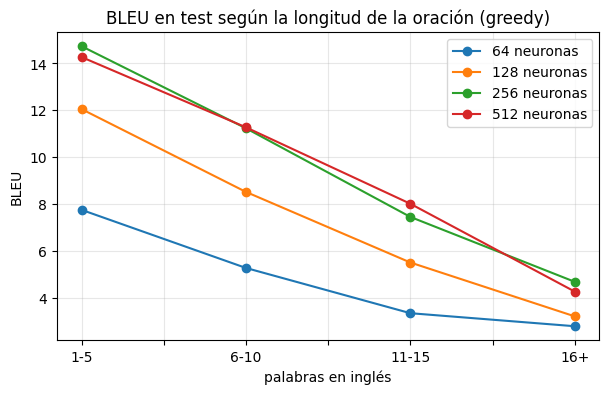

,oraciones de test,64 neuronas,128 neuronas,256 neuronas,512 neuronas
palabras en inglés,,,,,
1-5,974,7.76,12.05,14.73,14.27
6-10,1207,5.29,8.53,11.24,11.28
11-15,142,3.36,5.52,7.46,8.02
16+,13,2.80,3.22,4.70,4.28


In [20]:
length_bins = [0, 5, 10, 15, np.inf]
length_labels = ["1-5", "6-10", "11-15", "16+"]
test_bucket = pd.cut(test_en_len, bins=length_bins, labels=length_labels)

bleu_by_length = pd.DataFrame(
    {
        f"{n_units} neuronas": [
            bleu(
                [test_predictions[n_units][i] for i in np.where(test_bucket == label)[0]],
                [test_refs[i] for i in np.where(test_bucket == label)[0]],
            )
            for label in length_labels
        ]
        for n_units in runs
    },
    index=pd.Index(length_labels, name="palabras en inglés"),
)
bleu_by_length.insert(
    0, "oraciones de test", pd.Series(test_bucket).value_counts()[length_labels].values
)

bleu_by_length.drop(columns="oraciones de test").plot(marker="o", figsize=(7, 4))
plt.ylabel("BLEU")
plt.title("BLEU en test según la longitud de la oración (greedy)")
plt.grid(alpha=0.3)
plt.show()

bleu_by_length.round(2)

Lo primero si se cumple: en todos los modelos el BLEU baja conforme la oración es mas larga, mas o menos a la mitad entre las cortas y las de 11 a 15 palabras. Lo segundo no tanto: pasar de 64 a 256 neuronas mejora todos los largos casi por igual, y 512 apenas le gana a 256 en las de 11 a 15 palabras, una diferencia muy chiquita como para sacar conclusiones. El grupo de 16+ palabras tiene poquísimas oraciones, asi que ese punto yo lo tomaria con pinzas.


### Ejemplos de traducción

Agarré seis oraciones del test de distintos largos y las traduje con los cuatro modelos usando greedy. Tambien pongo hasta dos traducciones de referencia para comparar.


In [21]:
order = np.argsort(test_en_len, kind="stable")
example_positions = [order[int(q * (len(order) - 1))] for q in [0.1, 0.3, 0.5, 0.7, 0.9, 0.99]]

for k, pos in enumerate(example_positions, 1):
    i = test_idx[pos]
    print(f"[{k}] EN: {input_sentences[i]}")
    for ref in all_translations[input_sentences[i]][:2]:
        print(f"    referencia: {ref}")
    for n_units in runs:
        print(f"    {n_units:>4} neuronas: {' '.join(test_predictions[n_units][pos])}")
    print()

[1] EN: Tom is ill.
    referencia: Tom está malo.
      64 neuronas: tom está
     128 neuronas: tom está
     256 neuronas: tom está listo
     512 neuronas: tom está listo

[2] EN: I can peel an apple.
    referencia: Puedo pelar una manzana.
    referencia: Sé pelar una manzana.
      64 neuronas: puedo usar el piano
     128 neuronas: puedo usar el pelo
     256 neuronas: puedo usar un vaso de agua
     512 neuronas: puedo usar una lavadora

[3] EN: She was mad at her son.
    referencia: Ella estaba enojada con su hijo.
      64 neuronas: ella estaba en su hijo
     128 neuronas: ella estaba en un niño
     256 neuronas: ella estaba enfadada con sus padres
     512 neuronas: ella estaba enfadado con él

[4] EN: You should distinguish between right and wrong.
    referencia: Debe distinguir entre el bien y el mal.
      64 neuronas: deberías haber hecho algo de eso
     128 neuronas: deberías hablar con el punto de
     256 neuronas: deberías hablar con el asunto más difícil
     

In [22]:
# frases nuevas: las de clase y algunas más largas
new_sentences = [
    "My mother says hi.",
    "Where is the train station?",
    "I love learning languages.",
    "Can you help me?",
    "I don't think Tom knows where Mary lives.",
    "We should go to the beach tomorrow if the weather is good.",
    "She told me that she had never seen such a beautiful city before.",
]
new_predictions = {
    n_units: decode_batch(run, encode_english(new_sentences)) for n_units, run in runs.items()
}

for k, sentence in enumerate(new_sentences):
    print(f"EN: {sentence}")
    for n_units in runs:
        print(f"    {n_units:>4} neuronas: {' '.join(new_predictions[n_units][k])}")
    print()

EN: My mother says hi.
      64 neuronas: mi hermano le dio a mary
     128 neuronas: mi padre me llamó
     256 neuronas: mi madre me dijo a la madre
     512 neuronas: mi padre me llamó por teléfono

EN: Where is the train station?
      64 neuronas: dónde está el coche
     128 neuronas: dónde está el tren de la estación
     256 neuronas: dónde está el tren de la estación
     512 neuronas: dónde está el tren de aquí

EN: I love learning languages.
      64 neuronas: me gusta la música
     128 neuronas: hablo francés
     256 neuronas: me encanta aprender francés
     512 neuronas: me encantan los poemas breves

EN: Can you help me?
      64 neuronas: puedes ayudarme
     128 neuronas: puedes ayudarme
     256 neuronas: puedes ayudarme
     512 neuronas: puedes ayudarme

EN: I don't think Tom knows where Mary lives.
      64 neuronas: no sabía que tom no le gusta a mary
     128 neuronas: no sé qué tom vive en mary
     256 neuronas: no sé dónde vive tom tom
     512 neuronas: no 

Las frases cortas y muy comunes salen bien: _Can you help me?_ da `puedes ayudarme` en los cuatro modelos, y _Where is the train station?_ queda bastante cerca. Pero en cuanto aparece una palabra poco frecuente el modelo se la inventa: _I can peel an apple_ termina en `puedo usar un vaso de agua`. Tambien hay errores de concordancia (`ella estaba enfadado`), repeticiones (`tom tom`) y confusiones de personas (mamá por papá, hijo por padres).

En las oraciones largas casi siempre arranca bien y luego se pierde, como en _She told me that she had never seen such a beautiful city before_, que empieza con `ella me dijo que...` y termina hablando de otra cosa. Y se nota muchísimo el sesgo del corpus: _I love learning languages_ sale como `me encanta aprender francés`, seguro porque Tatoeba está lleno de oraciones sobre el francés.


### Opcional: otras estrategias de decodificación

Las comparo con el mejor modelo (el de mayor BLEU en test):

- Greedy: la palabra mas probable en cada paso. Si se equivoca al principio ya no hay forma de corregirlo.
- Beam search: en cada paso se queda con las `k` traducciones parciales mas probables y al final elige la mejor. Como la log-probabilidad siempre va sumando valores negativos, tiende a preferir traducciones cortas, entonces para compensar divido el puntaje por `largo ** alpha`.
- Muestreo con temperatura: en cada paso sortea la palabra segun la distribución del modelo. Con `T > 1` la distribución se aplana (mas variedad y mas errores) y con `T < 1` se concentra (se parece mas a greedy).


In [23]:
def beam_search(run, enc_seq, beam_width=3, alpha=0.7):
    """Traduce una oración con búsqueda por haz. Cada hipótesis: (palabras, log-prob, h, c)."""
    h, c = run["encoder"](enc_seq[None, :], training=False)
    beams = [([], 0.0, np.asarray(h)[0], np.asarray(c)[0])]
    finished = []
    for _ in range(max_out_len):
        last = np.array([[seq[-1] if seq else sos_idx] for seq, *_ in beams], dtype=np.int32)
        log_probs, h, c = decoder_step(
            run["decoder"], last, np.stack([b[2] for b in beams]), np.stack([b[3] for b in beams])
        )
        # cada hipótesis se extiende con sus beam_width palabras más probables
        candidates = []
        for b, (seq, score, _, _) in enumerate(beams):
            for idx in np.argsort(log_probs[b])[-beam_width:]:
                candidates.append((seq + [int(idx)], score + log_probs[b, idx], h[b], c[b]))
        candidates.sort(key=lambda cand: cand[1], reverse=True)

        # las que terminan en <eos> quedan completas; seguimos con las beam_width mejores del resto
        beams = []
        for cand in candidates:
            if cand[0][-1] == eos_idx:
                finished.append(cand)
            elif len(beams) < beam_width:
                beams.append(cand)
        if len(finished) >= beam_width or not beams:
            break

    best = max(finished or beams, key=lambda cand: cand[1] / len(cand[0]) ** alpha)
    return ids_to_words(best[0])


best_units = int(summary["BLEU test (greedy)"].idxmax())
best_run = runs[best_units]
print(f"Mejor configuración: {best_units} neuronas")

subset = np.arange(min(N_STRATEGY_EVAL, len(test_idx)))
subset_refs = [test_refs[i] for i in subset]
strategies = {
    "greedy": lambda: decode_batch(best_run, test_enc[subset]),
    "beam search (k=3)": lambda: [beam_search(best_run, test_enc[i], 3) for i in subset],
    "beam search (k=5)": lambda: [beam_search(best_run, test_enc[i], 5) for i in subset],
    "muestreo T=0.5": lambda: decode_batch(best_run, test_enc[subset], temperature=0.5),
    "muestreo T=1.0": lambda: decode_batch(best_run, test_enc[subset], temperature=1.0),
}
strategy_predictions = {}
strategy_rows = []
for name, decode in strategies.items():
    start = time.time()
    strategy_predictions[name] = decode()
    strategy_rows.append(
        {
            "estrategia": name,
            "BLEU": bleu(strategy_predictions[name], subset_refs),
            "palabras por traducción": np.mean([len(p) for p in strategy_predictions[name]]),
            "segundos": time.time() - start,
        }
    )
print(f"Primeras {len(subset)} oraciones de test")
strategy_summary = pd.DataFrame(strategy_rows).set_index("estrategia")
strategy_summary.round(2)

Mejor configuración: 256 neuronas
Primeras 500 oraciones de test


,BLEU,palabras por traducción,segundos
estrategia,,,
greedy,12.17,5.92,1.05
beam search (k=3),13.13,5.37,46.12
beam search (k=5),13.25,5.20,46.25
muestreo T=0.5,8.98,5.84,1.95
muestreo T=1.0,4.48,5.90,1.70


In [24]:
# las mismas oraciones de ejemplo con cada estrategia y varias muestras por temperatura
for pos in example_positions[2:5]:
    i = test_idx[pos]
    enc = test_enc[pos : pos + 1]
    print(f"EN: {input_sentences[i]}")
    print(f"    referencia:        {all_translations[input_sentences[i]][0]}")
    print(f"    greedy:            {' '.join(decode_batch(best_run, enc)[0])}")
    for k in (3, 5):
        print(f"    beam search (k={k}): {' '.join(beam_search(best_run, enc[0], k))}")
    for temperature in (0.5, 1.0, 1.5):
        for s in range(2):
            sample = decode_batch(best_run, enc, temperature=temperature, seed=s)[0]
            print(f"    muestreo T={temperature}:    {' '.join(sample)}")
    print()

EN: She was mad at her son.
    referencia:        Ella estaba enojada con su hijo.
    greedy:            ella estaba enfadada con sus padres
    beam search (k=3): ella estaba enfadada con él
    beam search (k=5): ella estaba enfadada con él
    muestreo T=0.5:    ella estaba a la misma edad
    muestreo T=0.5:    ella estaba sola y ella
    muestreo T=1.0:    ella estaba a la universidad
    muestreo T=1.0:    ella tenía un mirada a ellos
    muestreo T=1.5:    ella estaba en la bebida nerviosa
    muestreo T=1.5:    ella odiaba de sincero y mismo comenzó a cantar

EN: You should distinguish between right and wrong.
    referencia:        Debe distinguir entre el bien y el mal.
    greedy:            deberías hablar con el asunto más difícil
    beam search (k=3): deberías deshacerte de eso
    beam search (k=5): deberías deshacerte de eso
    muestreo T=0.5:    deberías hablar con la cabeza sin palabras
    muestreo T=0.5:    deberías deshacerte de esa manera
    muestreo T=1.0:  

Beam search le gana un poquito a greedy (en las mismas 500 oraciones), y pasar de `k=3` a `k=5` casi no cambia nada. Con beam las traducciones salen algo mas cortas y a veces mas naturales (`ella estaba enfadada con él` en vez de `con sus padres`), aunque no siempre mas correctas. Lo malo es que tarda muchísimo mas, porque va oración por oración.

El muestreo empeora el BLEU, y entre mas alta la temperatura, peor: con `T=1.5` ya salen frases sin sentido. Para traducir, donde hay una respuesta "correcta", muestrear no tiene mucho caso; sirve mas cuando quieres generar texto variado.


### Resumen

Junto todos los numeros en una sola salida para tenerlos a la mano.


In [25]:
print("=== Datos ===")
print(
    f"Pares: {len(pairs):,} | train {np.sum(split == 'train'):,} | val {np.sum(split == 'val'):,} "
    f"| oraciones de test {len(test_idx):,}"
)
print(
    f"max_input_len = {max_input_len} | max_out_len = {max_out_len} "
    f"(clase: {CLASS_MAX_INPUT_LEN} / {CLASS_MAX_OUT_LEN})"
)
print(f"Pares que la clase hubiera truncado: {n_truncated} ({n_lost_sos} perdían el <sos>)")
print(f"Posiciones de padding en el decoder: {pad_share:.1%}")
print(f"Vocabulario: {nb_words:,} (inglés) / {num_words_output:,} (español)")
print(
    f"Apariciones sin vector GloVe: {glove_missing_raw:.1%} sin separar contracciones -> "
    f"{glove_missing_split:.1%} separándolas"
)

print("\n=== Resumen por configuración ===")
print(summary.round(3).to_string())
print("\n=== BLEU por longitud de la oración en inglés ===")
print(bleu_by_length.round(2).to_string())
print(f"\n=== Estrategias de decodificación ({best_units} neuronas, {len(subset)} oraciones) ===")
print(strategy_summary.round(2).to_string())

gap = summary["train acc. sin padding"] - summary["val acc. sin padding"]
print("\nBrecha train - val en accuracy sin padding (en la mejor epoch):")
print(gap.round(3).to_string())

=== Datos ===
Pares: 50,000 | train 42,507 | val 5,008 | oraciones de test 2,336
max_input_len = 37 | max_out_len = 40 (clase: 20 / 22)
Pares que la clase hubiera truncado: 76 (39 perdían el <sos>)
Posiciones de padding en el decoder: 82.6%
Vocabulario: 9,707 (inglés) / 10,000 (español)
Apariciones sin vector GloVe: 4.8% sin separar contracciones -> 0.2% separándolas

=== Resumen por configuración ===
               parámetros entrenables mejor epoch / corridas  val loss  val perplejidad  train acc. sin padding  val acc. sin padding  BLEU test (greedy)  seg / epoch
neuronas LSTM                                                                                                                                                         
64                            1352464                30 / 30     3.468           32.085                   0.413                 0.395               5.586       17.435
128                           2793232                30 / 30     3.105           22.319       

### Interpretación

Sobre las métricas: la pérdida y la accuracy se miden con _teacher forcing_, o sea con el decoder recibiendo siempre la palabra correcta anterior, asi que son medio optimistas. Al traducir de verdad el modelo se alimenta de sus propias predicciones y un error al principio arrastra todo lo que sigue. Por eso le hago mas caso al BLEU, que se calcula sobre traducciones generadas de verdad. Igual vale la pena ver lo engañosa que era la accuracy de clase: como mas del 80% de las posiciones del decoder son padding, un modelo que no traduce nada ya sacaba mas de 80%, mientras que el mejor modelo, contando solo palabras reales, no le atina ni a la mitad.

El BLEU tampoco es perfecto. No reconoce sinónimos ni otras formas validas de decir lo mismo si no estan en las referencias, y en Tatoeba la mayoria de las oraciones tiene una sola referencia. Por ejemplo, las referencias traducen _Mary_ como "María" y el modelo deja `mary`, y eso le baja puntos aunque este bien. Por eso los valores son bajitos (alrededor de 11 para los mejores modelos); sirven mas para comparar configuraciones que como calificación de calidad.

Sobre el número de neuronas: agrandar las LSTM ayudó hasta 256. De 64 a 256 el BLEU se duplica, pero 512 queda practicamente empatado con 256 en BLEU y en accuracy, con peor pérdida de validación y tardando casi el doble por epoch. Con 512 el modelo tiene mas del doble de parámetros que con 256 pero los datos son los mismos 50.000 pares, y eso se ve en la brecha entre train y validación, que es la mas grande de los cuatro. Yo diria que a partir de 256 lo que limita es la cantidad de datos y no el tamaño del modelo.

Eso si, hay que tomar en cuenta que 64 y 128 llegaron al tope de 30 epochs todavia mejorando, asi que parte de su desventaja es que no terminaron de entrenar, no solo que sean mas chicos. Con mas epochs seguro mejorarian, y 128 en particular quedó bastante cerca de 256 en pérdida de validación, asi que no descartaria que lo alcance.

Sobre el largo de las oraciones: el BLEU cae con el largo en todos los modelos, que tiene sentido si toda la oración tiene que pasar por un solo vector de contexto. Agrandar el modelo sube todo mas o menos parejo, pero no arregla esa caida.

#### Limitaciones del enfoque

- No tiene atención. Toda la oración tiene que caber en un vector de tamaño fijo y con las oraciones largas se nota. Con atención el decoder podria ver todas las palabras del encoder en cada paso, que es lo que despues hacen los Transformers.
- Entrena viendo siempre el prefijo correcto, pero traduce a partir de sus propias predicciones (_exposure bias_). Greedy no puede corregir un error del principio; beam search ayuda un poco.
- El vocabulario es cerrado: lo que queda fuera de las 10.000 palabras se borra, asi que no puede generar nombres propios raros ni copiar palabras del inglés. Con tokenización por subpalabras (BPE, WordPiece) esto se evitaria.
- GloVe solo cubre el inglés y esta congelado. El embedding del español se aprende desde cero con 50.000 pares, que no es tanto.
- Tatoeba tiene oraciones cortas, coloquiales y bastante repetitivas (Tom, Mary, el francés...). El modelo funciona dentro de ese mundito, y las oraciones largas, que son las mas dificiles, son justo las que menos aparecen.


### Conclusiones

Usar mas datos y dejar las oraciones completas le dio al modelo mas variedad para aprender, pero en Tatoeba las oraciones largas siguen siendo pocas, asi que justo las mas dificiles son las que menos ve al entrenar.

Con las neuronas, mas grande no siempre es mejor. Hasta 256 cada aumento se notó bastante, pero 512 no tradujo mejor, tardó casi el doble y se sobreajustó. Para esta cantidad de datos 256 me pareció el punto justo, aunque ojo, los modelos chicos se quedaron cortos de epochs, entonces la comparación no es del todo pareja.

Tambien me di cuenta de lo importante que es elegir bien que medir. La accuracy contando el padding daba numeros altisimos que no decian nada; sin el padding y con BLEU el panorama es mucho mas realista (y mas humilde).

En cuanto a las traducciones, el modelo se defiende con frases cortas y comunes, pero con oraciones largas o palabras raras se pierde y se inventa cosas. Muchas veces la traducción suena a español correcto pero no dice lo mismo que el original, que es mas o menos lo que esperaba de un modelo sin atención y con tan pocos datos.

Beam search mejoró un poco respecto a greedy y vale la pena si el tiempo no importa. El muestreo con temperatura, en cambio, no tiene mucho caso para traducir: le da variedad pero a costa de errores.

Si tuviera que seguirle, lo primero que probaria es agregar atención, entrenar con mas datos y mas epochs, y usar tokenización por subpalabras.
